---
title: "Report Total Fraud"
author: "Muhammad Arif Budiman"
execute: true
format: docx
---

In [1]:
# | echo: false
from matplotlib.ticker import PercentFormatter
import os
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from IPython.display import Markdown, display

sns.set_theme(style="whitegrid")

DIR_FILE = Path.cwd()
ROOT_DIR = os.path.dirname(DIR_FILE)
DATASET_PATH = os.path.join(
    ROOT_DIR, "dataset", "credit_card_fraud_detection_2026.csv"
)
df = pd.read_csv(DATASET_PATH)

n_total = len(df)
n_fraud = int(df["is_fraud"].sum())
baseline = n_fraud / n_total

In [2]:
# | echo: false
display(Markdown(
    f"Dataset berisi **{n_total:,}** transaksi dan **{df.shape[1]}** kolom."
))
df.info()

Dataset berisi **100,000** transaksi dan **43** kolom.

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   transaction_id               100000 non-null  str    
 1   customer_id                  100000 non-null  str    
 2   card_id                      100000 non-null  str    
 3   merchant_id                  100000 non-null  str    
 4   transaction_datetime         100000 non-null  str    
 5   transaction_amount           100000 non-null  float64
 6   merchant_category            100000 non-null  str    
 7   merchant_country             100000 non-null  str    
 8   transaction_hour             100000 non-null  int64  
 9   transaction_day_of_week      100000 non-null  str    
 10  card_present                 100000 non-null  int64  
 11  customer_age                 100000 non-null  int64  
 12  customer_gender              100000 non-null  str    
 13  customer_st

### 2.2 Ringkasan Numerik

In [3]:
# | echo: false
num_cols = ["transaction_amount", "customer_age", "account_age_days",
            "credit_limit", "credit_score"]
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
transaction_amount,100000.0,126.87,276.18,0.5,21.28,52.26,129.72,15000.0
customer_age,100000.0,42.22,14.25,18.0,32.00,42.00,52.00,85.0
account_age_days,100000.0,785.45,747.49,1.0,233.00,554.00,1103.00,3650.0
credit_limit,100000.0,10083.18,6510.65,500.0,5000.00,8500.00,13650.00,36670.0
credit_score,100000.0,682.33,92.12,328.0,620.00,683.00,748.00,850.0


### 2.3 Missing Value & Cek Konsistensi

In [4]:
# | echo: false
miss = df.isna().sum()
miss = miss[miss > 0].rename("n_missing").to_frame()
miss["pct"] = (miss["n_missing"] / n_total * 100).round(2)
display(miss)

checks = pd.DataFrame({
    "cek": [
        "browser kosong == channel In-store/ATM",
        "fraud_type != Legitimate == is_fraud",
    ],
    "lolos": [
        bool((df["browser"].isna() ==
              df["transaction_channel"].isin(["In-store", "ATM"])).all()),
        bool(((df["fraud_type"] != "Legitimate").astype(int)
              == df["is_fraud"]).all()),
    ],
})
display(checks)

,n_missing,pct
browser,41709,41.71


,cek,lolos
0,browser kosong == channel In-store/ATM,True
1,fraud_type != Legitimate == is_fraud,True


Kolom `browser` kosong secara struktural (transaksi non-online), jadi tidak
di-impute.

### 2.4 Distribusi Fraud

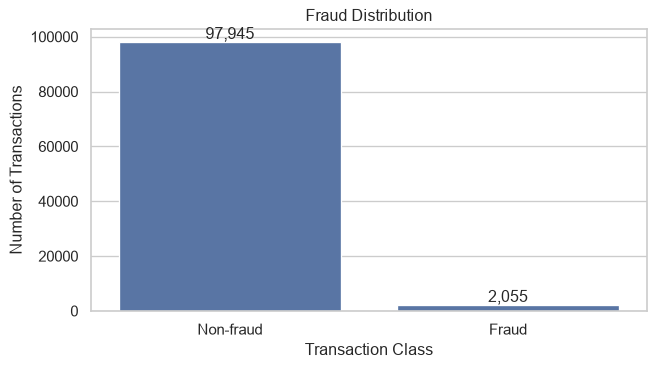

- Fraud: **2,055** dari 100,000 transaksi (**2.05%**).
- Data sangat imbalanced; angka 2.05% dipakai sebagai baseline di analisis berikutnya.

In [5]:
# | echo: false
counts = (df["is_fraud"].map({0: "Non-fraud", 1: "Fraud"})
          .value_counts().reindex(["Non-fraud", "Fraud"]))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_title("Fraud Distribution")
ax.set_xlabel("Transaction Class")
ax.set_ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

display(Markdown(
    f"- Fraud: **{n_fraud:,}** dari {n_total:,} transaksi "
    f"(**{baseline:.2%}**).\n"
    f"- Data sangat imbalanced; angka {baseline:.2%} dipakai sebagai "
    f"baseline di analisis berikutnya."
))

## 3. Exploratory Data Analysis

### 3.1 Nilai Transaksi: Fraud vs Non-fraud

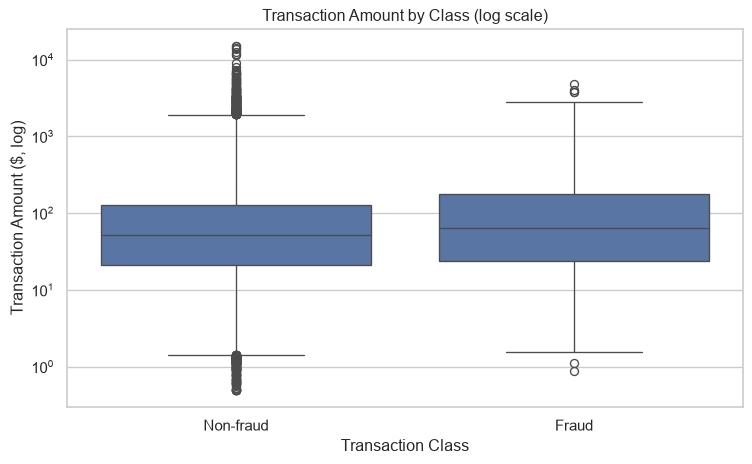

- Median nilai transaksi: non-fraud **\$52.06**, fraud **\$64.80** (rasio 1.2x).

In [6]:
# | echo: false
plot_df = df.assign(
    kelas=df["is_fraud"].map({0: "Non-fraud", 1: "Fraud"})
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=plot_df, x="kelas", y="transaction_amount",
            order=["Non-fraud", "Fraud"], log_scale=True, ax=ax)
ax.set_title("Transaction Amount by Class (log scale)")
ax.set_xlabel("Transaction Class")
ax.set_ylabel("Transaction Amount ($, log)")
plt.tight_layout()
plt.show()

med = df.groupby("is_fraud")["transaction_amount"].median()
display(Markdown(
    f"- Median nilai transaksi: non-fraud **\\${med[0]:,.2f}**, "
    f"fraud **\\${med[1]:,.2f}** "
    f"(rasio {med[1] / med[0]:.1f}x)."
))

### 3.2 Fraud Amount Analysis

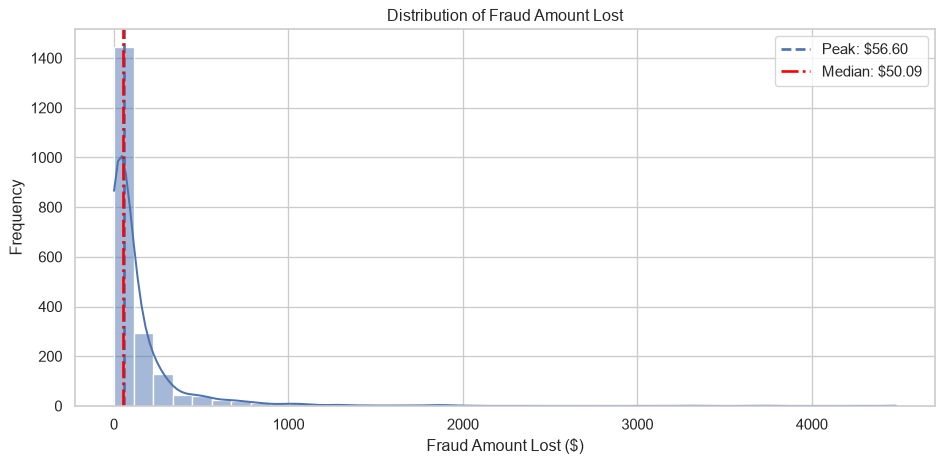

- Total kerugian: **\$279,842**; rata-rata \$136.18, median \$50.09.
- Kerugian terbesar: **\$4,482.16**; puncak distribusi di sekitar \$57.
- Rata-rata > median menandakan distribusi miring ke kanan.

In [7]:
# | echo: false
fraud_data = df.loc[df["is_fraud"] == 1].copy()

median_loss = fraud_data["fraud_amount_lost"].median()
mean_loss = fraud_data["fraud_amount_lost"].mean()
max_loss = fraud_data["fraud_amount_lost"].max()
total_loss = fraud_data["fraud_amount_lost"].sum()

# puncak histogram menggantikan mode() (data kontinu)
hist_vals, edges = np.histogram(fraud_data["fraud_amount_lost"], bins=40)
peak = (edges[hist_vals.argmax()] + edges[hist_vals.argmax() + 1]) / 2

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=fraud_data, x="fraud_amount_lost", bins=40,
             kde=True, ax=ax)
ax.axvline(peak, linestyle="--", linewidth=2,
           label=f"Peak: ${peak:,.2f}")
ax.axvline(median_loss, linestyle="-.", linewidth=2, color="red",
           label=f"Median: ${median_loss:,.2f}")
ax.set_title("Distribution of Fraud Amount Lost")
ax.set_xlabel("Fraud Amount Lost ($)")
ax.set_ylabel("Frequency")
ax.legend()
plt.tight_layout()
plt.show()

display(Markdown(
    f"- Total kerugian: **\\${total_loss:,.0f}**; "
    f"rata-rata \\${mean_loss:,.2f}, median \\${median_loss:,.2f}.\n"
    f"- Kerugian terbesar: **\\${max_loss:,.2f}**; "
    f"puncak distribusi di sekitar \\${peak:,.0f}.\n"
    f"- Rata-rata > median menandakan distribusi miring ke kanan."
))

In [8]:
# | echo: false


def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h


def rate_table(data, col, min_n=500):
    g = (data.groupby(col)
         .agg(n=("is_fraud", "size"), fraud=("is_fraud", "sum"))
         .reset_index())
    g = g[g["n"] >= min_n].copy()  # segmen < min_n tidak diranking
    g["rate"] = g["fraud"] / g["n"]
    g["lift"] = g["rate"] / baseline
    g["lo"], g["hi"] = wilson(g["fraud"], g["n"])
    return g


def plot_rate(g, col, title, order=None, figsize=(8, 5), fs=10):
    if order is not None:
        g = g.set_index(col).loc[order].reset_index()
    else:
        g = g.sort_values("rate", ascending=False)
    fig, ax = plt.subplots(figsize=figsize)
    sns.barplot(data=g, y=col, x="rate", order=g[col].tolist(),
                color="C0", ax=ax)
    ax.errorbar(g["rate"].values, np.arange(len(g)),
                xerr=[(g["rate"] - g["lo"]).values,
                      (g["hi"] - g["rate"]).values],
                fmt="none", ecolor="black", capsize=2, lw=1)
    ax.axvline(baseline, ls="--", color="red",
               label=f"Baseline {baseline:.2%}")
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    ax.tick_params(axis="y", labelsize=fs)
    ax.set_title(title)
    ax.set_xlabel("Fraud Rate (95% CI)")
    ax.set_ylabel("")
    ax.legend()
    plt.tight_layout()
    plt.show()


def summarize(g, col):
    s = g.sort_values("rate")
    top, low = s.iloc[-1], s.iloc[0]
    n_sig = int((g["lo"] > baseline).sum())
    display(Markdown(
        f"- Tertinggi: **{top[col]}** {top['rate']:.2%} "
        f"(lift {top['lift']:.2f}x; {int(top['fraud'])} fraud dari "
        f"{int(top['n']):,}).\n"
        f"- Terendah: **{low[col]}** {low['rate']:.2%} "
        f"(lift {low['lift']:.2f}x).\n"
        f"- {n_sig} dari {len(g)} segmen punya batas bawah CI di atas "
        f"baseline."
    ))

### 3.3 Temporal

#### 3.3.1 Fraud Rate per Jam


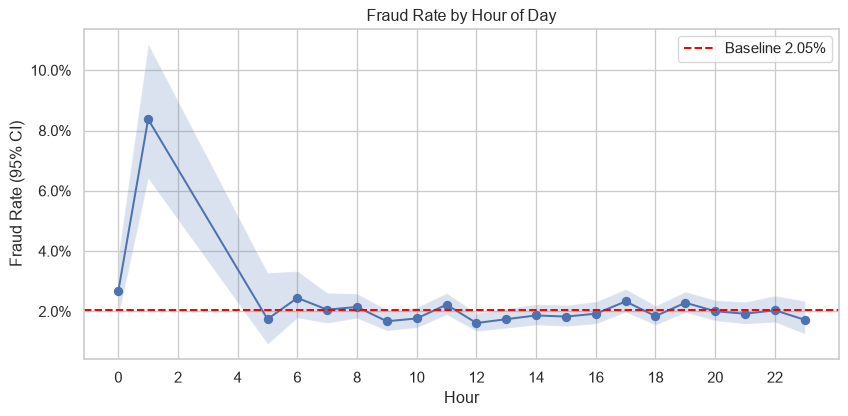

- Jam tertinggi: **01:00** (8.38%), **00:00** (2.67%), **06:00** (2.45%).
- 1 dari 24 jam punya batas bawah CI di atas baseline.

In [9]:
# | echo: false
g = rate_table(df, "transaction_hour")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(g["transaction_hour"], g["rate"], marker="o", color="C0")
ax.fill_between(g["transaction_hour"], g["lo"], g["hi"], alpha=0.2)
ax.axhline(baseline, ls="--", color="red",
           label=f"Baseline {baseline:.2%}")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.set_xticks(range(0, 24, 2))
ax.set_title("Fraud Rate by Hour of Day")
ax.set_xlabel("Hour")
ax.set_ylabel("Fraud Rate (95% CI)")
ax.legend()
plt.tight_layout()
plt.show()

top3 = g.nlargest(3, "rate")
display(Markdown(
    "- Jam tertinggi: " + ", ".join(
        f"**{int(h):02d}:00** ({r:.2%})"
        for h, r in zip(top3["transaction_hour"], top3["rate"])) + ".\n"
    f"- {int((g['lo'] > baseline).sum())} dari 24 jam punya batas bawah "
    f"CI di atas baseline."
))

#### 3.3.2 Fraud Rate per Hari

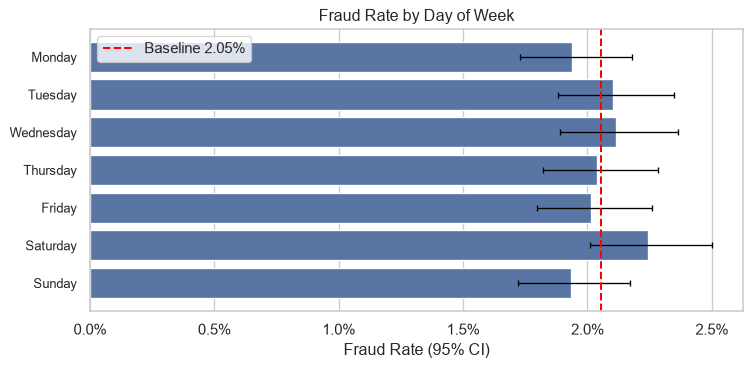

- Tertinggi: **Saturday** 2.24% (lift 1.09x; 317 fraud dari 14,133).
- Terendah: **Sunday** 1.93% (lift 0.94x).
- 0 dari 7 segmen punya batas bawah CI di atas baseline.

In [10]:
# %%
# | echo: false
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday",
        "Saturday", "Sunday"]
g = rate_table(df, "transaction_day_of_week")
plot_rate(g, "transaction_day_of_week", "Fraud Rate by Day of Week",
          order=days, figsize=(8, 4))
summarize(g, "transaction_day_of_week")

### 3.4 Kategorikal

- Pembanding semua plot adalah baseline fraud rate keseluruhan (garis
merah). Lift = rate segmen / baseline. Segmen < 500 transaksi tidak
diranking.

#### 3.4.1 Negara Merchant

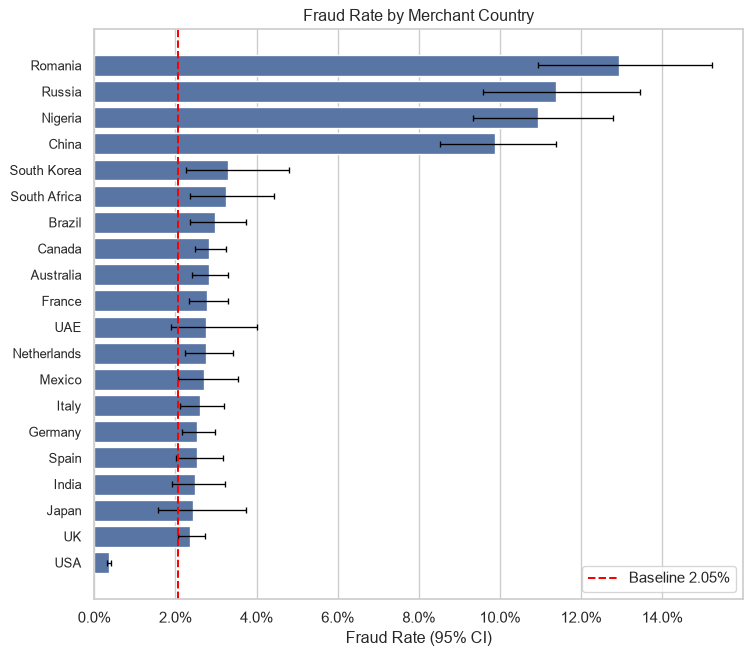

- Tertinggi: **Romania** 12.94% (lift 6.30x; 122 fraud dari 943).
- Terendah: **USA** 0.35% (lift 0.17x).
- 15 dari 20 segmen punya batas bawah CI di atas baseline.

,merchant_country,n,fraud,share_fraud,share_volume
2,Canada,7238,205,0.0998,0.0724
18,UK,8349,198,0.0964,0.0835
3,China,1682,166,0.0808,0.0168
19,USA,44515,157,0.0764,0.4452
0,Australia,5423,153,0.0745,0.0542


In [11]:
# | echo: false
g = rate_table(df, "merchant_country")
plot_rate(g, "merchant_country", "Fraud Rate by Merchant Country",
          figsize=(8, 7))
summarize(g, "merchant_country")

share = (g.assign(share_fraud=g["fraud"] / g["fraud"].sum(),
                  share_volume=g["n"] / g["n"].sum())
         .nlargest(5, "share_fraud")
         [["merchant_country", "n", "fraud", "share_fraud",
           "share_volume"]]
         .round(4))
display(share)

- Tabel di atas: 5 negara penyumbang fraud terbanyak, dibandingkan share fraud vs share volume transaksinya.

#### 3.4.2 Kategori Merchant

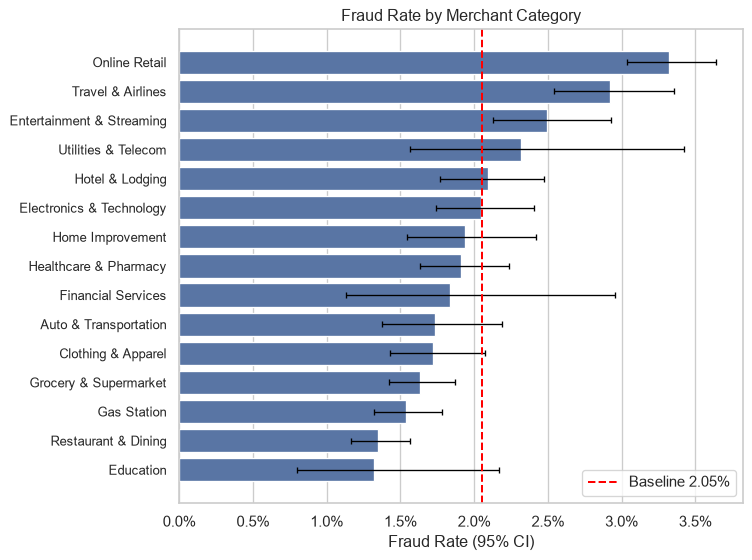

- Tertinggi: **Online Retail** 3.32% (lift 1.62x; 446 fraud dari 13,417).
- Terendah: **Education** 1.32% (lift 0.64x).
- 3 dari 15 segmen punya batas bawah CI di atas baseline.

In [12]:
# | echo: false
g = rate_table(df, "merchant_category")
plot_rate(g, "merchant_category", "Fraud Rate by Merchant Category",
          figsize=(8, 6))
summarize(g, "merchant_category")

#### 3.4.3 Channel dan Browser

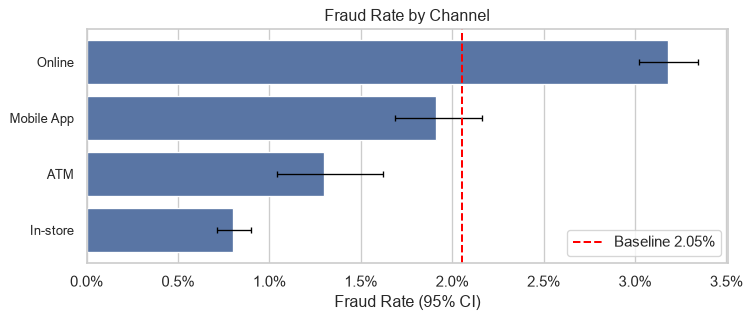

- Tertinggi: **Online** 3.18% (lift 1.55x; 1447 fraud dari 45,532).
- Terendah: **In-store** 0.80% (lift 0.39x).
- 1 dari 4 segmen punya batas bawah CI di atas baseline.

In [13]:
# | echo: false
g = rate_table(df, "transaction_channel")
plot_rate(g, "transaction_channel", "Fraud Rate by Channel",
          figsize=(8, 3.5))
summarize(g, "transaction_channel")

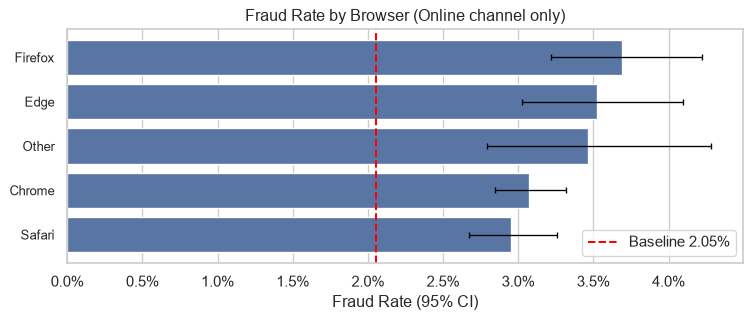

- Tertinggi: **Firefox** 3.69% (lift 1.80x; 201 fraud dari 5,448).
- Terendah: **Safari** 2.95% (lift 1.44x).
- 5 dari 5 segmen punya batas bawah CI di atas baseline.

In [14]:
# | echo: false
g = rate_table(df[df["transaction_channel"] == "Online"], "browser")
plot_rate(g, "browser", "Fraud Rate by Browser (Online channel only)",
          figsize=(8, 3.5))
summarize(g, "browser")

#### 3.4.4 Email Domain dan Gender

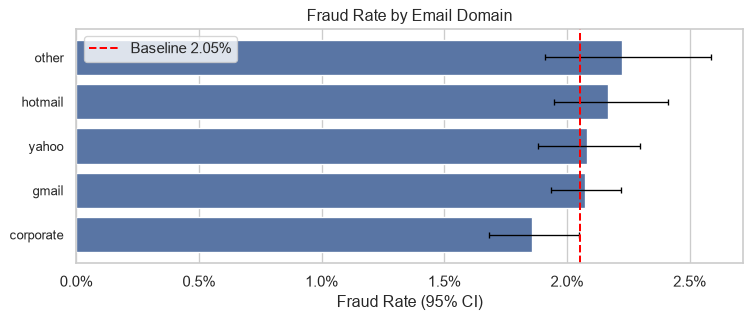

- Tertinggi: **other** 2.22% (lift 1.08x; 163 fraud dari 7,327).
- Terendah: **corporate** 1.86% (lift 0.90x).
- 0 dari 5 segmen punya batas bawah CI di atas baseline.

In [15]:
# | echo: false
g = rate_table(df, "email_domain")
plot_rate(g, "email_domain", "Fraud Rate by Email Domain",
          figsize=(8, 3.5))
summarize(g, "email_domain")

In [16]:
# | echo: false
display(Markdown("Gender: deskriptif saja, tidak dijadikan kandidat aturan."))
display(rate_table(df, "customer_gender", min_n=0)
        [["customer_gender", "n", "fraud", "rate", "lift"]].round(4))

Gender: deskriptif saja, tidak dijadikan kandidat aturan.

,customer_gender,n,fraud,rate,lift
0,Female,50641,1041,0.0206,1.0003
1,Male,47573,972,0.0204,0.9942
2,Other,1786,42,0.0235,1.1443


#### 3.4.5 Jenis Fraud

,n,total,mean,median,share_n,share_loss
fraud_type,,,,,,
Card-Not-Present,1054,150504.04,142.79,50.86,0.51,0.54
Account-Takeover,447,62294.02,139.36,52.00,0.22,0.22
Synthetic-Identity,309,34860.41,112.82,43.97,0.15,0.12
Card-Present,245,32183.73,131.36,48.62,0.12,0.12


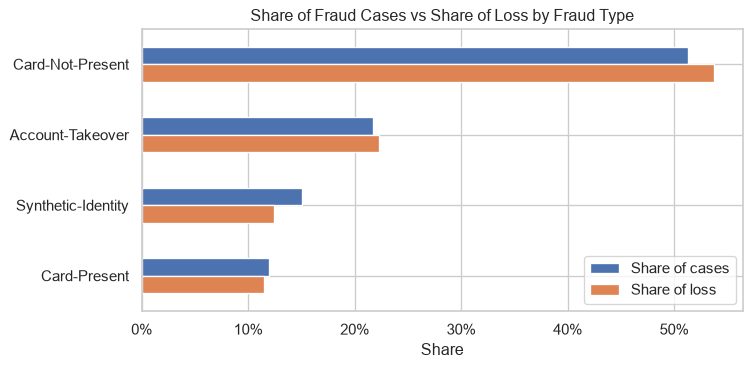

- Penyumbang kerugian terbesar: **Card-Not-Present** (53.8% dari total kerugian, 51.3% dari jumlah kasus).

In [17]:
# | echo: false
fd = df[df["is_fraud"] == 1]
ft = (fd.groupby("fraud_type")["fraud_amount_lost"]
      .agg(n="size", total="sum", mean="mean", median="median")
      .sort_values("total", ascending=False))
ft["share_n"] = ft["n"] / ft["n"].sum()
ft["share_loss"] = ft["total"] / ft["total"].sum()
display(ft.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ft[["share_n", "share_loss"]].plot.barh(ax=ax)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title("Share of Fraud Cases vs Share of Loss by Fraud Type")
ax.set_xlabel("Share")
ax.set_ylabel("")
ax.legend(["Share of cases", "Share of loss"])
plt.tight_layout()
plt.show()

top_loss = ft.index[0]
display(Markdown(
    f"- Penyumbang kerugian terbesar: **{top_loss}** "
    f"({ft.loc[top_loss, 'share_loss']:.1%} dari total kerugian, "
    f"{ft.loc[top_loss, 'share_n']:.1%} dari jumlah kasus)."
))

#### 3.4.6 Lampiran: State Pelanggan

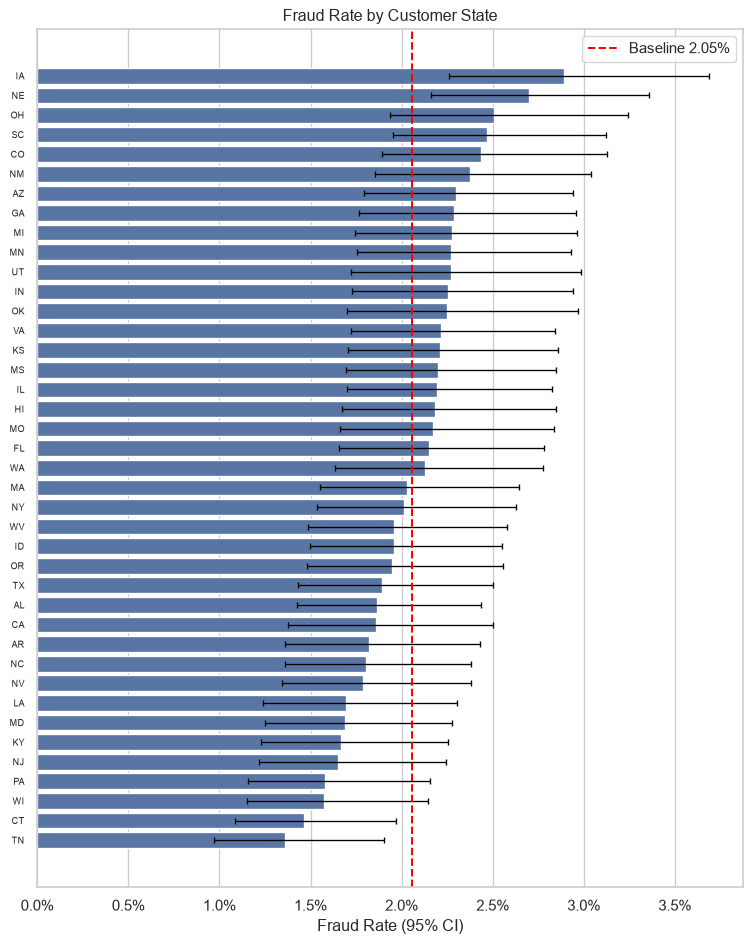

- Tertinggi: **IA** 2.89% (lift 1.41x; 62 fraud dari 2,144).
- Terendah: **TN** 1.36% (lift 0.66x).
- 2 dari 40 segmen punya batas bawah CI di atas baseline.

In [18]:
# | echo: false
g = rate_table(df, "customer_state")
plot_rate(g, "customer_state", "Fraud Rate by Customer State",
          figsize=(8, 10), fs=7)
summarize(g, "customer_state")